In [11]:
from dotenv import load_dotenv
load_dotenv()

import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  # pour heatmap corrélation

from utils import load_data

plt.rcParams["figure.figsize"] = (10, 5)
load_data.clear()

df_act = load_data("data/activities_clean.csv")
print(f"df_act : {len(df_act)} sorties, {len(df_act.columns)} colonnes")
df_act.info()

2026-09-27 13:57:19.732 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


df_act : 131 sorties, 30 colonnes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131 entries, 0 to 130
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype    
---  ------                  --------------  -----    
 0   id                      131 non-null    int64    
 1   name                    131 non-null    object   
 2   sport_type              131 non-null    object   
 3   manual                  131 non-null    bool     
 4   flagged                 131 non-null    bool     
 5   start_date_local        131 non-null    object   
 6   moving_time_seconds     131 non-null    int64    
 7   average_speed_m_s       131 non-null    float64  
 8   max_speed_m_s           131 non-null    float64  
 9   total_elevation_gain_m  131 non-null    float64  
 10  elev_high_m             131 non-null    float64  
 11  elev_low_m              131 non-null    float64  
 12  average_heartrate       13 non-null     float64  
 13  max_heartrate           13 non-

# Stats descriptives + NA

In [12]:
# Variables quantitatives candidates pour l'analyse
QUANTI = [
    "distance_km", "moving_time_seconds", "pace_min_km", "average_speed_m_s",
    "total_elevation_gain_m", "elev_high_m", "elev_low_m",
    "pause_seconds", "pr_count", "suffer_score",
    "weather_temperature", "weather_humidity", "weather_precipitation",
]

# Stats descriptives
print("=== Stats descriptives ===")
print(df_act[QUANTI].describe().round(2).T)

# NA par colonne
print("\n=== NA par colonne ===")
na_counts = df_act[QUANTI].isna().sum()
na_pct = 100 * na_counts / len(df_act)
print(pd.DataFrame({"n_na": na_counts, "pct_na": na_pct.round(1)}))

# Constantes ou quasi-constantes ?
print("\n=== Constantes / booléennes ===")
for c in ["sport_type", "manual", "flagged"]:
    print(f"{c}: {df_act[c].value_counts().to_dict()}")

=== Stats descriptives ===
                        count     mean      std    min     25%      50%  \
distance_km             131.0     5.36     4.79   0.29    2.37     4.73   
moving_time_seconds     131.0  1652.27  1678.80  92.00  694.50  1368.00   
pace_min_km             131.0     5.00     0.79   3.63    4.40     4.85   
average_speed_m_s       131.0     3.41     0.50   2.34    3.13     3.43   
total_elevation_gain_m  131.0    28.08    31.79   0.00   11.70    18.10   
elev_high_m             131.0   143.31   230.09   9.20   45.50    55.80   
elev_low_m              131.0   122.73   218.39   3.20   30.65    40.70   
pause_seconds           131.0    84.91   272.43   0.00    0.00     4.00   
pr_count                131.0     0.32     0.95   0.00    0.00     0.00   
suffer_score            123.0    55.15    76.48   0.00   14.50    39.00   
weather_temperature     131.0    16.35     5.90   0.20   13.50    16.80   
weather_humidity        131.0    71.08    14.90  32.00   60.50    72.00  

# Histogrammes

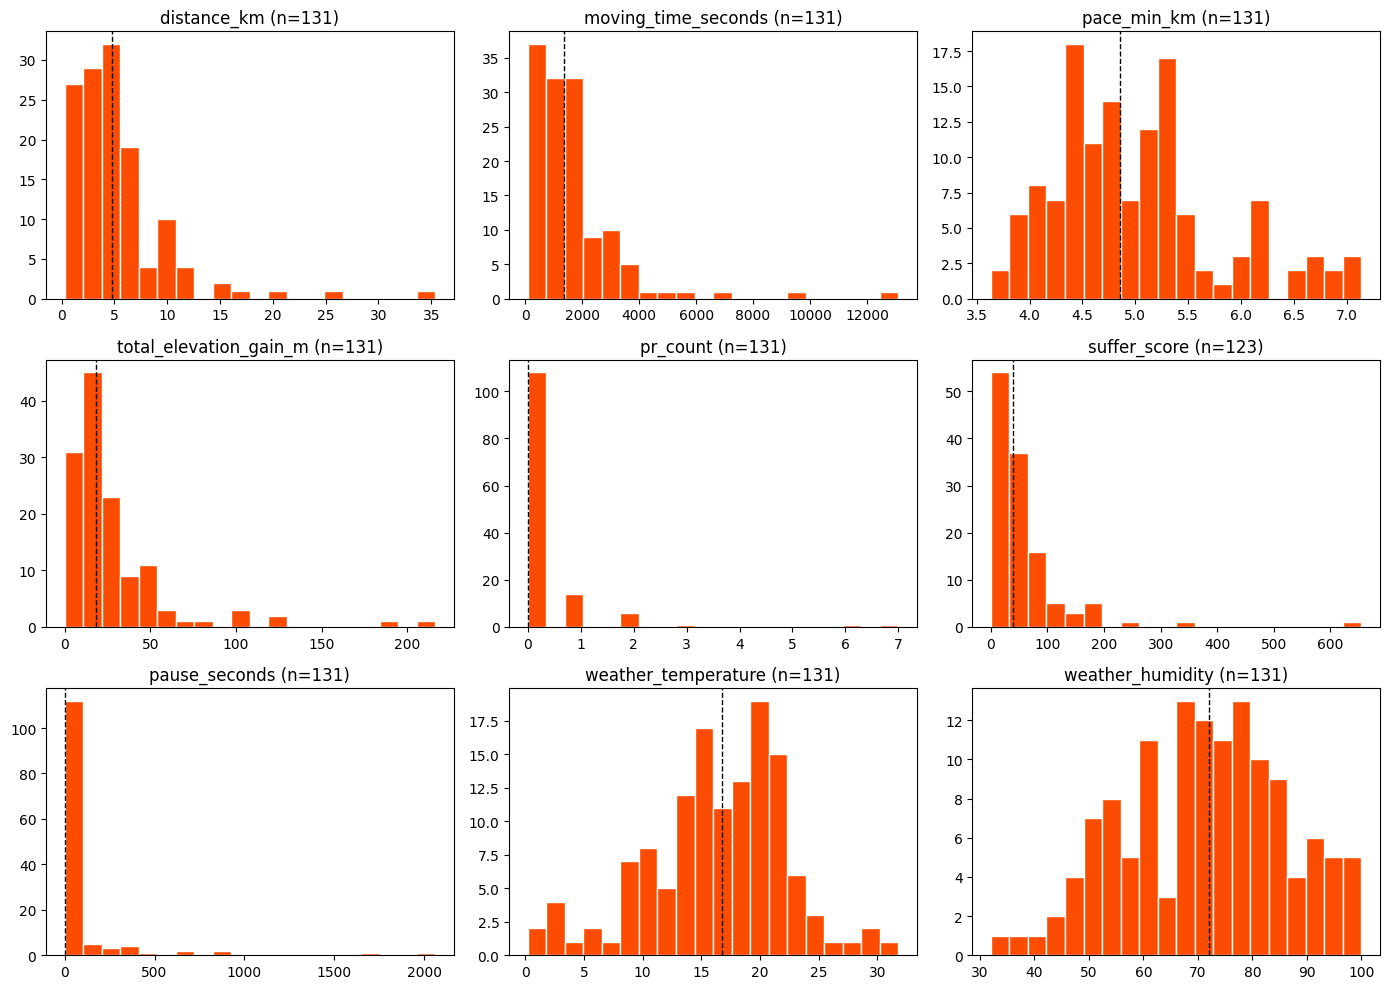

In [13]:
# Sélection des variables à distribuer
HIST_VARS = [
    "distance_km", "moving_time_seconds", "pace_min_km",
    "total_elevation_gain_m", "pr_count", "suffer_score",
    "pause_seconds", "weather_temperature", "weather_humidity",
]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, HIST_VARS):
    data = df_act[col].dropna()
    ax.hist(data, bins=20, color="#FC4C02", edgecolor="white")
    ax.set_title(f"{col} (n={len(data)})")
    ax.axvline(data.median(), color="black", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

# Boxplots par catégories

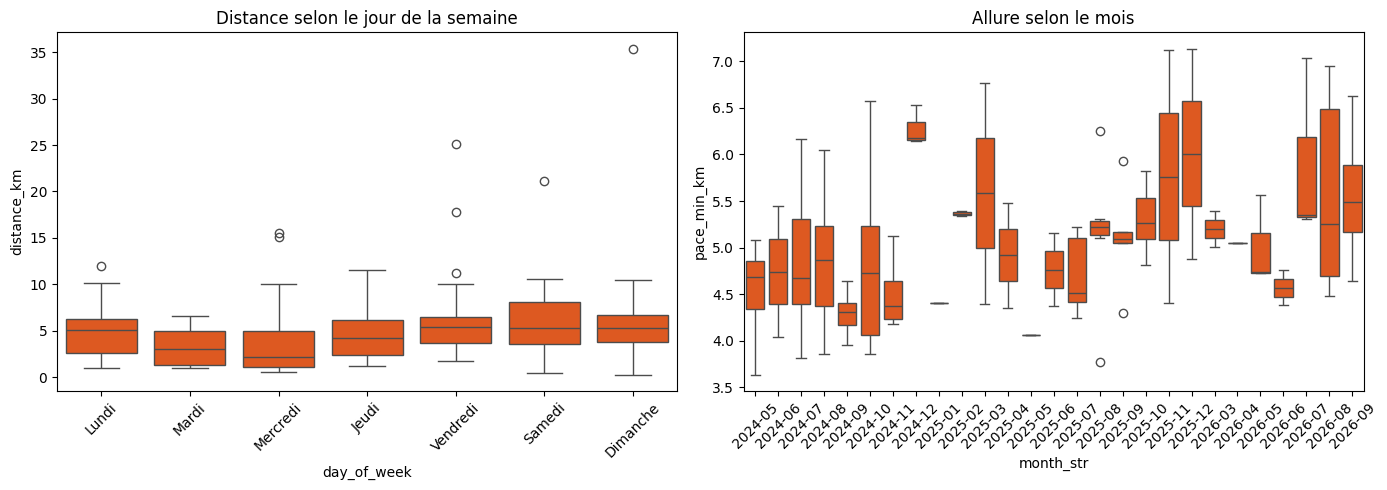

Sorties par jour de semaine :
day_of_week
Lundi       18
Mardi       17
Mercredi    21
Jeudi       17
Vendredi    18
Samedi      13
Dimanche    27
Name: count, dtype: int64


In [14]:
# Deux visualisations rapides : par jour de semaine et par mois
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Par jour de semaine
order = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
sns.boxplot(data=df_act, x="day_of_week", y="distance_km", order=order,
            ax=axes[0], color="#FC4C02")
axes[0].set_title("Distance selon le jour de la semaine")
axes[0].tick_params(axis="x", rotation=45)

# Par mois
df_plot = df_act.copy()
df_plot["month_str"] = df_plot["month"].astype(str)
sns.boxplot(data=df_plot.sort_values("month"), x="month_str", y="pace_min_km",
            ax=axes[1], color="#FC4C02")
axes[1].set_title("Allure selon le mois")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Effectif par catégorie
print("Sorties par jour de semaine :")
print(df_act["day_of_week"].value_counts().reindex(order))

# Matrice de corrélation

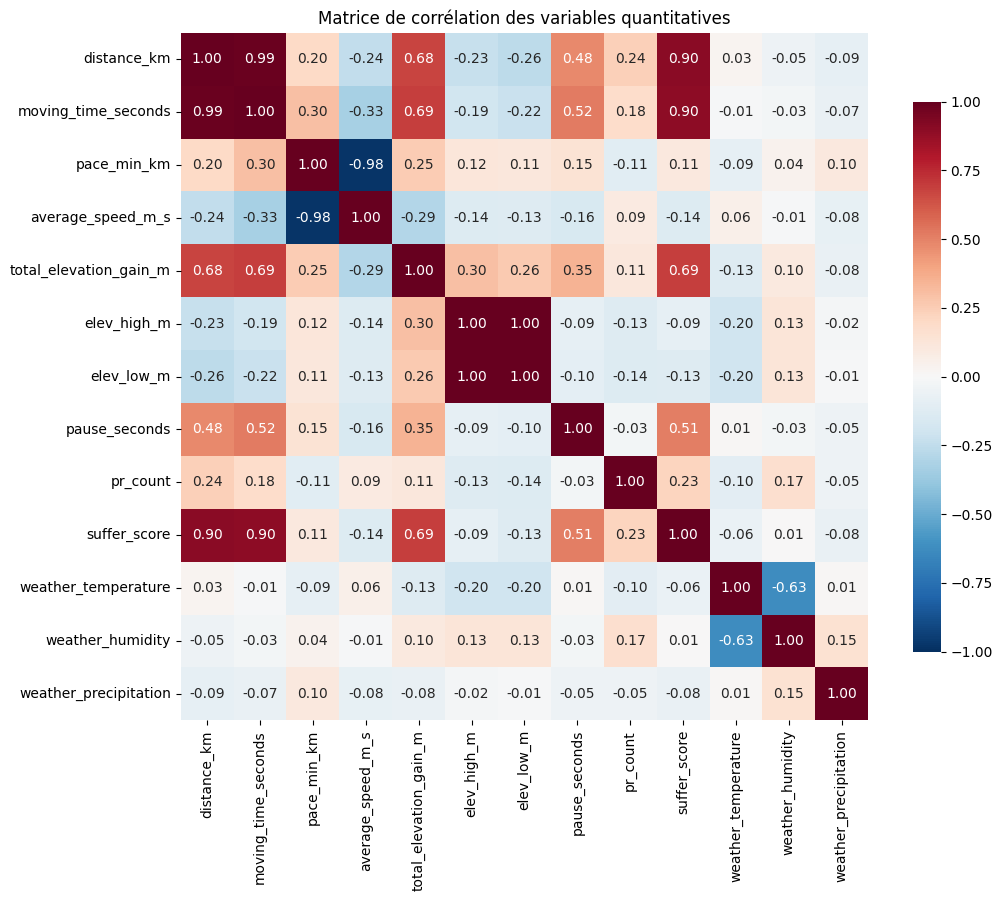


=== Paires |corr| > 0.7 ===
elev_high_m          elev_low_m             0.999
distance_km          moving_time_seconds    0.988
pace_min_km          average_speed_m_s      0.983
distance_km          suffer_score           0.900
moving_time_seconds  suffer_score           0.897
dtype: float64


In [15]:
# Matrice de corr sur les quanti (dropna pour être sûr)
corr = df_act[QUANTI].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Matrice de corrélation des variables quantitatives")
plt.tight_layout()
plt.show()

# Paires très corrélées à surveiller pour l'ACP
print("\n=== Paires |corr| > 0.7 ===")
c = corr.abs()
upper = c.where(np.triu(np.ones_like(c, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print(pairs[pairs > 0.7].round(3))

# Outliers candidats

In [16]:
# Approche IQR : marquer les valeurs > Q3 + 3×IQR ou < Q1 - 3×IQR
def flag_outliers(s, k=3):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return (s < lo) | (s > hi)

flags = pd.DataFrame({
    col: flag_outliers(df_act[col].dropna()) for col in QUANTI
})

# Compter les sorties outliers par colonne
print("=== Nombre de sorties outliers par variable (règle IQR k=3) ===")
print(flags.sum().sort_values(ascending=False))

# Sorties outliers sur plusieurs variables
n_out_per_row = flags.sum(axis=1)
suspect_ids = df_act.loc[n_out_per_row >= 2, "id"].tolist()
print(f"\n{len(suspect_ids)} sorties outliers sur ≥ 2 variables :")
if suspect_ids:
    print(df_act[df_act["id"].isin(suspect_ids)][
        ["id", "name", "distance_km", "pace_min_km", "total_elevation_gain_m", "pause_seconds"]
    ].to_string(index=False))

=== Nombre de sorties outliers par variable (règle IQR k=3) ===
pr_count                  23
elev_high_m               19
pause_seconds             19
elev_low_m                18
weather_precipitation     15
total_elevation_gain_m     7
distance_km                3
moving_time_seconds        3
suffer_score               3
pace_min_km                0
average_speed_m_s          0
weather_temperature        0
weather_humidity           0
dtype: object

27 sorties outliers sur ≥ 2 variables :
         id                            name  distance_km  pace_min_km  total_elevation_gain_m  pause_seconds
16486365552 Course à pied dans l'après-midi       2.1875     7.122507                    49.1             11
16439594522           Course à pied de nuit       0.6024     4.398698                     0.0              0
16118782896 Course à pied dans l'après-midi       1.8194     5.817336                    62.4              0
16110861556           Course à pied de nuit       0.2911     5.26759

In [17]:
print(df_act[df_act["suffer_score"].isna()][["id", "name", "date_fr", "distance_km"]])

              id                             name            date_fr  \
40   15617615157            Course à pied le soir       28 août 2025   
41   15617495839  Course à pied dans l'après-midi       28 août 2025   
79   12460776025            Course à pied le soir  20 septembre 2024   
89   12115137871            Course à pied de nuit       10 août 2024   
96   12021989511            Course à pied le soir    30 juillet 2024   
109  11779632537           Course à pied matinale     1 juillet 2024   
110  11779601402           Course à pied matinale     1 juillet 2024   
114  11533808019            Course à pied le soir        30 mai 2024   

     distance_km  
40        1.2609  
41        1.3064  
79        6.5845  
89        3.6471  
96        5.5880  
109       1.0017  
110       2.5967  
114       1.3907  
